# 3 · The constraint diagram

Every requirement as T/W(W/S), with the AERO-03 engine's thrust lapse.
Lesson: [03](../docs/lessons/03-constraint-diagram.md) ·
Theory: [constraint analysis](../docs/constraint_analysis.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from acdesign import plotting as P
from acdesign.requirements import B737_800_MISSION as M
from acdesign.units import FT, G0, LB, NMI

P.use_style()
np.set_printoptions(precision=4, suppress=True)
sys.path.insert(0, "../validation")  # cited reference data and the reference aircraft
from reference import b737_800

R = b737_800()
from acdesign.constraint_analysis import constraint_diagram
from acdesign.external.engine import Engine
from constraint_validation import reference_polar

In [2]:
e = Engine()
for h, Mach, rating in [(0, 0.2, 1.0), (10668, 0.78, 0.92)]:
    print(f"lapse at {h:5.0f} m, Mach {Mach}, rating {rating}: {float(e.lapse(h, Mach, rating)):.3f}")

lapse at     0 m, Mach 0.2, rating 1.0: 0.828
lapse at 10668 m, Mach 0.78, rating 0.92: 0.249


design point (5961.70770253139, 0.285056900500192) set by take-off field length


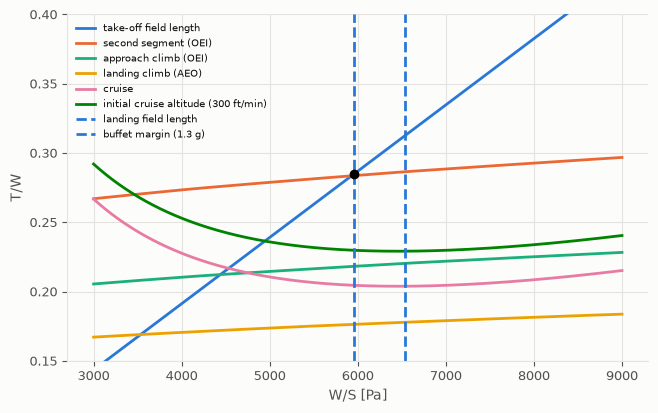

In [3]:
polar = reference_polar()
d = constraint_diagram(M, polar, e)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, tw in d.tw.items():
    ax.plot(d.ws, tw, label=name)
for name, ws in d.ws_max.items():
    ax.axvline(ws, ls="--", label=name)
ax.plot(*d.design, "ko")
ax.set_ylim(0.15, 0.4); ax.set_xlabel("W/S [Pa]"); ax.set_ylabel("T/W"); ax.legend(fontsize=7);
print("design point", d.design, "set by", d.active(d.design[0]))

Change a requirement: a 1,500 m landing field moves the wing-loading limit.

In [4]:
from dataclasses import replace

d2 = constraint_diagram(replace(M, landing_field_length=1500.0), polar, e)
print(f"W/S limit {d.ws_limit:,.0f} Pa -> {d2.ws_limit:,.0f} Pa; T/W {d.design[1]:.3f} -> {d2.design[1]:.3f}")

W/S limit 5,962 Pa -> 5,058 Pa; T/W 0.285 -> 0.279
